**Chiller Digital Twin 1: Condenser Fouling, COP and Compressor Power**

Cooling water deposits scale and biological growth on the condenser tubes. The fouling layer adds a thermal resistance $R_f$, so the overall heat transfer coefficient falls, $U = 1/(1/U_{clean} + R_f)$, and the condenser needs a larger temperature difference to reject the same heat. The condensing pressure rises, the compressor has to work harder and the COP falls.

We look at two ways the chiller can respond:

* **(a) Fixed refrigerant flow**: the compressor runs at constant capacity. The cooling capacity drops and the chilled water leaves warmer.
* **(b) Fixed chilled water supply (7 °C)**: the chiller increases its capacity to keep meeting the cooling load, which is how a real chiller is controlled. This shows the true energy penalty of fouling.

Typical fouling resistances: 0.000176 m²K/W for treated cooling tower water (TEMA), 0.00035 m²K/W for untreated tower water.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
from chiller import setup_chiller_model, chiller_results

# Build, initialize and solve the chiller at its design point
model, results = setup_chiller_model()
print(results.solver.termination_condition)
cop_clean = chiller_results(model)["COP"]
print("Design COP: {0:.3f}".format(cop_clean))

The DOF is 0
optimal
Design COP: 4.563


## Fouling sweep

In [3]:
from chiller_case_studies import fouling_sweep

fouling = [0, 0.000176, 0.00035, 0.0005, 0.001]
fixed_flow = fouling_sweep(model, fouling, mode="fixed_flow")
fixed_supply = fouling_sweep(model, fouling, mode="fixed_supply")

columns = ["U (W/m2K)", "Condenser pressure (bar)", "Discharge temperature (C)", "Chilled water supply (C)",
           "Cooling duty (kW)", "Compressor power (kW)", "COP"]
print("(a) Fixed refrigerant flow")
display(fixed_flow[columns])
print("(b) Fixed chilled water supply, 7 C")
display(fixed_supply[columns + ["Refrigerant flow (kg/s)"]])

(a) Fixed refrigerant flow


,U (W/m2K),Condenser pressure (bar),Discharge temperature (C),Chilled water supply (C),Cooling duty (kW),Compressor power (kW),COP
Fouling resistance (m2K/W),,,,,,,
0.000000,1000.000000,10.164083,56.642805,7.007601,20.948665,4.590812,4.563172
0.000176,850.340136,10.679618,58.827531,7.095003,20.581531,4.767883,4.316702
0.000350,740.740741,11.208663,60.977100,7.182012,20.216063,4.940416,4.091976
0.000500,666.666667,11.678027,62.812628,7.257113,19.900626,5.086368,3.912542
0.001000,500.000000,13.316140,68.763107,7.505748,18.856390,5.550336,3.397342


(b) Fixed chilled water supply, 7 C


,U (W/m2K),Condenser pressure (bar),Discharge temperature (C),Chilled water supply (C),Cooling duty (kW),Compressor power (kW),COP,Refrigerant flow (kg/s)
Fouling resistance (m2K/W),,,,,,,,
0.000000,1000.000000,10.169529,56.671418,7.0,20.980594,4.602629,4.558393,0.137742
0.000176,850.340136,10.766942,59.252627,7.0,20.980594,4.931367,4.254519,0.140676
0.000350,740.740741,11.417102,61.925065,7.0,20.980594,5.286248,3.968901,0.143894
0.000500,666.666667,12.028785,64.322811,7.0,20.980594,5.618276,3.734347,0.146950
0.001000,500.000000,14.485605,73.017607,7.0,20.980594,6.948537,3.019426,0.159608


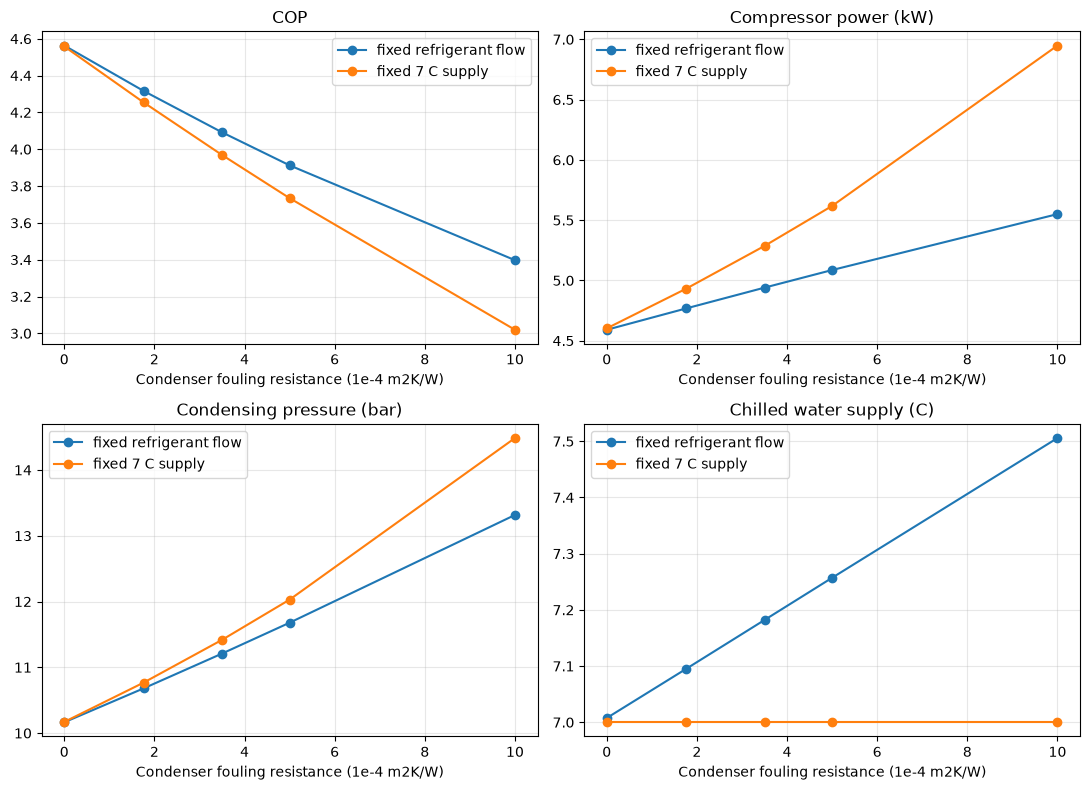

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for df, label in ((fixed_flow, "fixed refrigerant flow"), (fixed_supply, "fixed 7 C supply")):
    x = df.index * 1e4
    axes[0, 0].plot(x, df["COP"], "o-", label=label)
    axes[0, 1].plot(x, df["Compressor power (kW)"], "o-", label=label)
    axes[1, 0].plot(x, df["Condenser pressure (bar)"], "o-", label=label)
    axes[1, 1].plot(x, df["Chilled water supply (C)"], "o-", label=label)
for ax, title in zip(axes.flat, ["COP", "Compressor power (kW)", "Condensing pressure (bar)", "Chilled water supply (C)"]):
    ax.set_title(title)
    ax.set_xlabel("Condenser fouling resistance (1e-4 m2K/W)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## The cycle on the P-h diagram

The fouled cycle (fixed refrigerant flow) condenses at a higher pressure, so the compression line is longer: more work for less refrigeration.

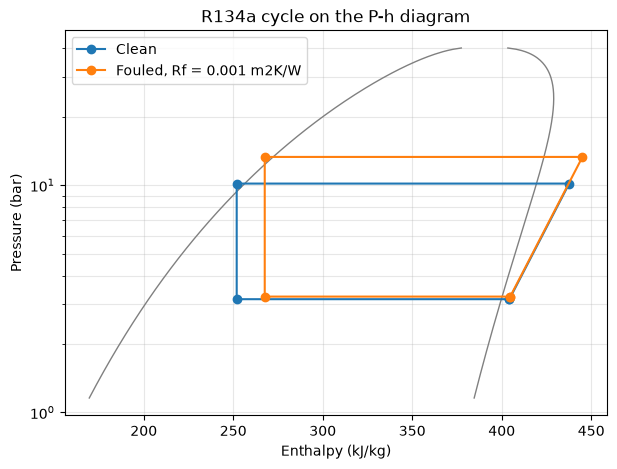

In [5]:
from chiller import cycle_points, plot_ph
from chiller_case_studies import set_fouling, step_to

cycles = {"Clean": cycle_points(model)}
step_to(model, lambda m, rf: set_fouling(m, condenser=rf), 0.0, 0.001)
cycles["Fouled, Rf = 0.001 m2K/W"] = cycle_points(model)
step_to(model, lambda m, rf: set_fouling(m, condenser=rf), 0.001, 0.0)

fig, ax = plt.subplots(figsize=(7, 5))
plot_ph(ax, cycles)
plt.show()